<a href="https://colab.research.google.com/github/Mxrtmlk/Talleres-tica/blob/main/Taller_sumativo_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 3: Modelos interpretables y xAI <h2><center>  




# `Instrucciones generales`

Esta es la parte III del proyecto, considerá ultizar tus resultados anteriores
y reciclar el código anterior.

## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3


In [ ]:
# Coloque aquí todas las importaciones que considere necesarias.
from transformers import pipeline
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt
import shap



# Parte 1: Interpretabilidad local con LIME

## Motivación

Un modelo de clasificación de texto puede tener buen desempeño agregado y aun así fallar sistemáticamente ante ciertos tipos de lenguaje: eufemismos, tecnicismos, formas indirectas de comunicar una noticia, o lenguaje cargado políticamente. Estas fallas suelen ser invisibles si solo miramos métricas globales o si confiamos ciegamente en el sistema. LIME permite explorar una predicción individual y preguntar: ¿qué palabras llevaron al modelo a decidir esto? Esto es especialmente relevante cuando el texto que se clasifica admite múltiples interpretaciones, tiene una carga social relevante y, en definitiva, forma parte de un sistema con consecuencias reales sobre las personas.

En esta parte van a diseñar un pequeño experimento: eligen un contexto de riesgo asociado a su proyecto, construyen frases que pongan a prueba ese riesgo específico, y usan LIME para ver si el modelo efectivamente falla (o no) de la manera que hipotetizaron.

## Parte 1.1: Contexto

Lo primero que deben hacer es definir el contexto de su análisis. Dependiendo del proyecto que su grupo haya escogido, elijan un escenario en el que un sistema sociotécnico relacionado con su dataset tuviera que clasificar lenguaje, y en el que un error de clasificación tuviera una consecuencia concreta. Por ejemplo:

- **CIRI**: un sistema que clasifica declaraciones oficiales de gobiernos para detectar lenguaje que minimiza o niega violaciones a los derechos humanos.

- **Breast Cancer**: un sistema que analiza cómo se comunica un diagnóstico a pacientes.

- **CASEN**: un sistema que clasifica comunicaciones de resultados de ayudas sociales.

**Responder:**

0. Explica los conceptos clave: XAI, LIME y SHAP y lo que se busca hacer con estos en el contexto del taller.

1. Describan el escenario de riesgo que eligieron: ¿qué tipo de frases van a analizar y por qué esas frases son relevantes para ese escenario? Creen o recopilen al menos 10 frases.

## Parte 1.2: Aplicación de LIME

1. Carguen el modelo BETO de análisis de sentimientos.

2. Obtengan la predicción del modelo para cada frase y comparen los resultados con su hipótesis de 1.1: ¿se cumplió lo que esperaban?

3. Apliquen LIME para obtener la explicación local de al menos 5 frases, priorizando aquellas donde el modelo se comportó de forma inesperada o donde identifiquen un problema ético. Si no encuentran ningún problema, justifiquen esa conclusión. Para cada una, visualicen las contribuciones de cada palabra mediante un gráfico de barras.

4. Interpreten los resultados: ¿qué palabras están dominando cada predicción? ¿El modelo se apoya en las palabras que ustedes esperaban, o en otras? ¿Identifican un problema ético o social en los resultados?

XAI es un conjunto de técnicas y herramientas que buscan que las decisiones tomadas por un modelo de IA sean comprensibles para las personas, evitando que funcionen como una caja negra. Por su parte, LIME es una técnica de XAI cuyo objetivo principal es explicar predicciones individuales, su funcionamiento se basa en alterar ligeramente un texto o dato de entrada para observar cómo cambia la predicción del modelo e identificar qué palabras o elementos específicos llevaron al sistema a tomar dicha decisión. En cuanto a SHAP, es una herramienta de XAI que calcula la contribución exacta de cada palabra o variable a la predicción final de una forma más global. Finalmente, en este taller buscamos utilizar LIME para analizar y evaluar un modelo de clasificación de texto, con el propósito de comprobar si este falla sistemáticamente ante sesgos, eufemismos, tecnicismos o lenguaje políticamente cargado que las métricas globales, no logran evidenciar.

Seleccionamos un sistema automatizado de procesamiento de comunicaciones y apelaciones de ayudas sociales, este es basado en datos de la encuesta CASEN. El riesgo está en que el modelo falle al evaluar la urgencia de un caso debido a sesgos lingüísticos, desestimando erróneamente solicitudes de familias vulnerables.

Analizaremos 10 frases que abarcan reclamos directos, situaciones de cesantía, mensajes con carga política, empleo informal, redes de apoyo y expresiones ambiguas. Estas frases son relevantes porque permiten analizar si el modelo comprende la vulnerabilidad real de fondo o si se deja sesgar por factores superficiales, como el uso de lenguaje informal, eufemismos o tecnicismos.

Frase 1: Oye, ¿qué les pasa? ¿Cómo no me van a dar el beneficio si no tengo ni pa' comer?

Frase 2: Hola, me gustaría que se revaluara la situación de mi postulación al beneficio, dado que consideramos injusta la respuesta negativa obtenida, considerando que nuestros ingresos actuales son sumamente precarios.

Frase 3: No tengo pega hace rato y tengo tres cabros chicos que casi ni comen, por obligación me deberían dar el beneficio.

Frase 4: Hola, me gustaría exponer mi situación, me encuentro desempleado desde hace un año y tengo tres hijos a mi cargo. Debido a esta crisis, se me ha hecho insostenible cubrir sus necesidades básicas, por lo que solicito que se considere mi caso para acceder a una ayuda.

Frase 5: ¿Cómo va a ser que sean tan incompetentes pa' no darnos algo tan básico como la canasta mensual? Son nefastos, este gobierno nunca nos aporta nada de lo que se supone que nos prometen.

Frase 6: El sistema de asignación de ayudas tiene deficiencias graves al negar recursos básicos como la canasta mensual a familias vulnerables, la gestión estatal actual está fallando en su deber de protección social.

Frase 7: He estado haciendo puras pegas ocasionales en la feria, y como vivo de allegado con un familiar ultimamente, necesito que me consideren en el catastro.

Frase 8: Presento ingresos intermitentes debido a labores informales de comercio callejero y residencia compartida con familiares, por lo que solicito la validación de mi condición de vulnerabilidad habitacional y laboral.

Frase 9: No puedo salir a buscar un contrato fijo porque paso todo el día cuidando a mi mamá postrada y sin red de apoyo médica, por lo que dependemos enteramente de que nos aprueben este subsidio de emergencia.

Frase 10: En el papel aparezco con puntaje alto porque el año pasado trabajé dos meses, pero la realidad es que hoy estamos sin un solo peso en la casa y la ficha CASEN no refleja mi urgencia actual.

In [2]:
!pip install transformers lime torch -q

"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


In [3]:
clasificador = pipeline(
    "sentiment-analysis",
    model="finiteautomata/beto-sentiment-analysis",
    tokenizer="finiteautomata/beto-sentiment-analysis"
)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

C:\Users\pokem\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pokem\.cache\huggingface\hub\models--finiteautomata--beto-sentiment-analysis. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\pokem\AppData\Local\Programs\Python\Python312\Lib\site-packages\hu

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/528 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  439MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/481k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [4]:
def predecir_proba(textos):
    """
    Envuelve el pipeline de Hugging Face en el formato que espera LIME:
    recibe una lista de textos y retorna una matriz (n_textos x 3) con
    probabilidades para las clases NEG, NEU y POS.

    Aproximación: la probabilidad de la clase predicha es el score del modelo;
    el resto se distribuye uniformemente entre las otras dos clases.
    """
    etiquetas = ["NEG", "NEU", "POS"]  # orden fijo requerido por LimeTextExplainer
    resultados = clasificador(list(textos), top_k=None)
    probas = []
    for r in resultados:
        scores = {d["label"]: d["score"] for d in r}
        probas.append([scores[e] for e in etiquetas])
    return np.array(probas)

# Instanciamos el explicador LIME con los nombres de las clases del modelo
explainer = LimeTextExplainer(class_names=["NEG", "NEU", "POS"])

In [5]:
frases_casen = [
    "Oye, ¿qué les pasa? ¿Cómo no me van a dar el beneficio si no tengo ni pa' comer?",
    "Hola, me gustaría que se revaluara la situación de mi postulación al beneficio, dado que consideramos injusta la respuesta negativa obtenida, considerando que nuestros ingresos actuales son sumamente precarios.",
    "No tengo pega hace rato y tengo tres cabros chicos que casi ni comen, por obligación me deberían dar el beneficio.",
    "Hola, me gustaría exponer mi situación, me encuentro desempleado desde hace un año y tengo tres hijos a mi cargo. Debido a esta crisis, se me has hecho insostenible cubrir sus necesidades básicas, por lo que solicito que se considere mi caso para acceder a una ayuda.",
    "¿Cómo va a ser que sean tan incompetentes pa' no darnos algo tan básico como la canasta mensual? Son nefastos, este gobierno nunca nos aporta nada de lo que se supone que nos prometen.",
    "El sistema de asignación de ayudas tiene deficiencias graves al negar recursos básicos como la canasta mensual a familias vulnerables, la gestión estatal actual está fallando en su deber de protección social.",
    "He estado haciendo puras pegas ocasionales en la feria, y como vivo de allegado con un familiar ultimamente, necesito que me consideren en el catastro.",
    "Presento ingresos intermitentes debido a labores informales de comercio callejero y residencia compartida con familiares, por lo que solicito la validación de mi condición de vulnerabilidad habitacional y laboral.",
    "No puedo salir a buscar un contrato fijo porque paso todo el día cuidando a mi mamá postrada y sin red de apoyo médica, por lo que dependemos enteramente de que nos aprueben este subsidio de emergencia.",
    "En el papel aparezco con puntaje alto porque el año pasado trabajé dos meses, pero la realidad es que hoy estamos sin un solo peso en la casa y la ficha CASEN no refleja mi urgencia actual."
]

print("--- Predicciones iniciales del modelo  ---\n")
for i, frase in enumerate(frases_casen, 1):
    probs = predecir_proba([frase])[0]
    clase_idx = int(np.argmax(probs))
    nombre_clase = explainer.class_names[clase_idx]
    print(f"Frase {i}: {nombre_clase} |Confianza: {probs[clase_idx]:.2%}| -> {frase}\n")

--- Predicciones iniciales del modelo  ---

Frase 1: NEG |Confianza: 99.86%| -> Oye, ¿qué les pasa? ¿Cómo no me van a dar el beneficio si no tengo ni pa' comer?

Frase 2: NEG |Confianza: 96.03%| -> Hola, me gustaría que se revaluara la situación de mi postulación al beneficio, dado que consideramos injusta la respuesta negativa obtenida, considerando que nuestros ingresos actuales son sumamente precarios.

Frase 3: NEG |Confianza: 99.93%| -> No tengo pega hace rato y tengo tres cabros chicos que casi ni comen, por obligación me deberían dar el beneficio.

Frase 4: NEG |Confianza: 99.26%| -> Hola, me gustaría exponer mi situación, me encuentro desempleado desde hace un año y tengo tres hijos a mi cargo. Debido a esta crisis, se me has hecho insostenible cubrir sus necesidades básicas, por lo que solicito que se considere mi caso para acceder a una ayuda.

Frase 5: NEG |Confianza: 99.92%| -> ¿Cómo va a ser que sean tan incompetentes pa' no darnos algo tan básico como la canasta mensual? 

Las predicciones del modelo evidencian que este etiqueta como negativo casi todos los reclamos y situaciones críticas con altas confianzas, sin lograr distinguir entre un tono airado con coloquialismos y una solicitud formal y respetuosa de ayuda socioeconómica. Asimismo, hipótesis contrastadas como las frases 7 y 8 fueron clasificadas como neutras a pesar de describir una precariedad laboral e habitacional, lo que demuestra que el modelo es incapaz de detectar la vulnerabilidad estructural si esta se enuncia mediante jerga popular o un tono descriptivo más plano.


================ LIME - Frase 1 ================


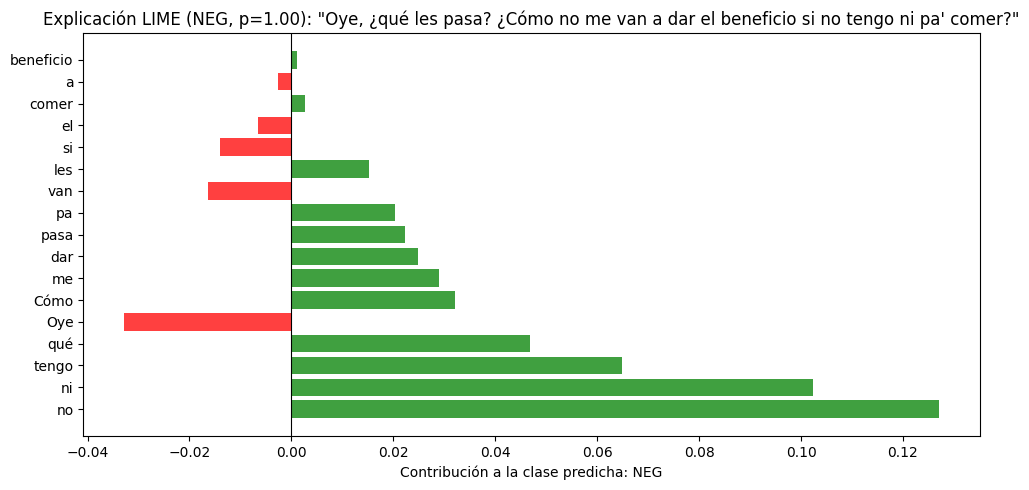


================ LIME - Frase 2 ================


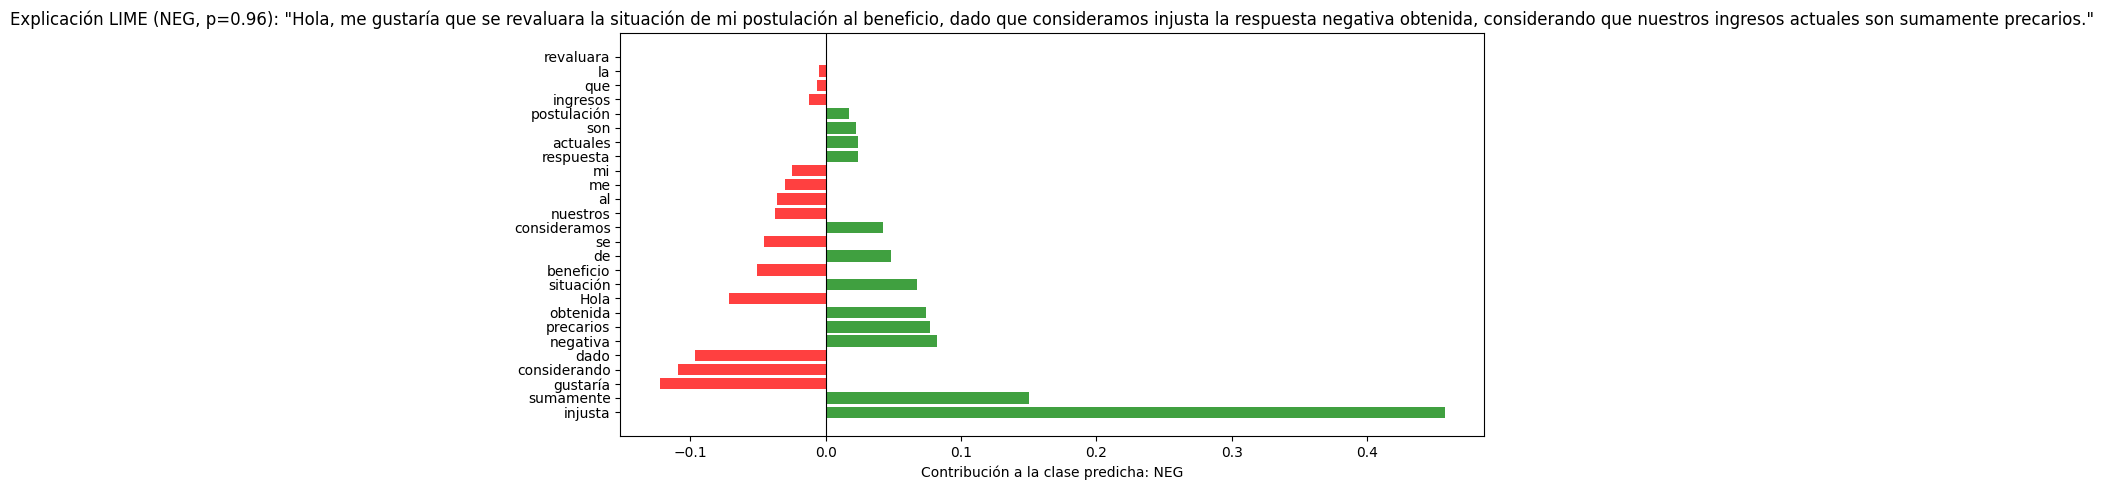


================ LIME - Frase 5 ================


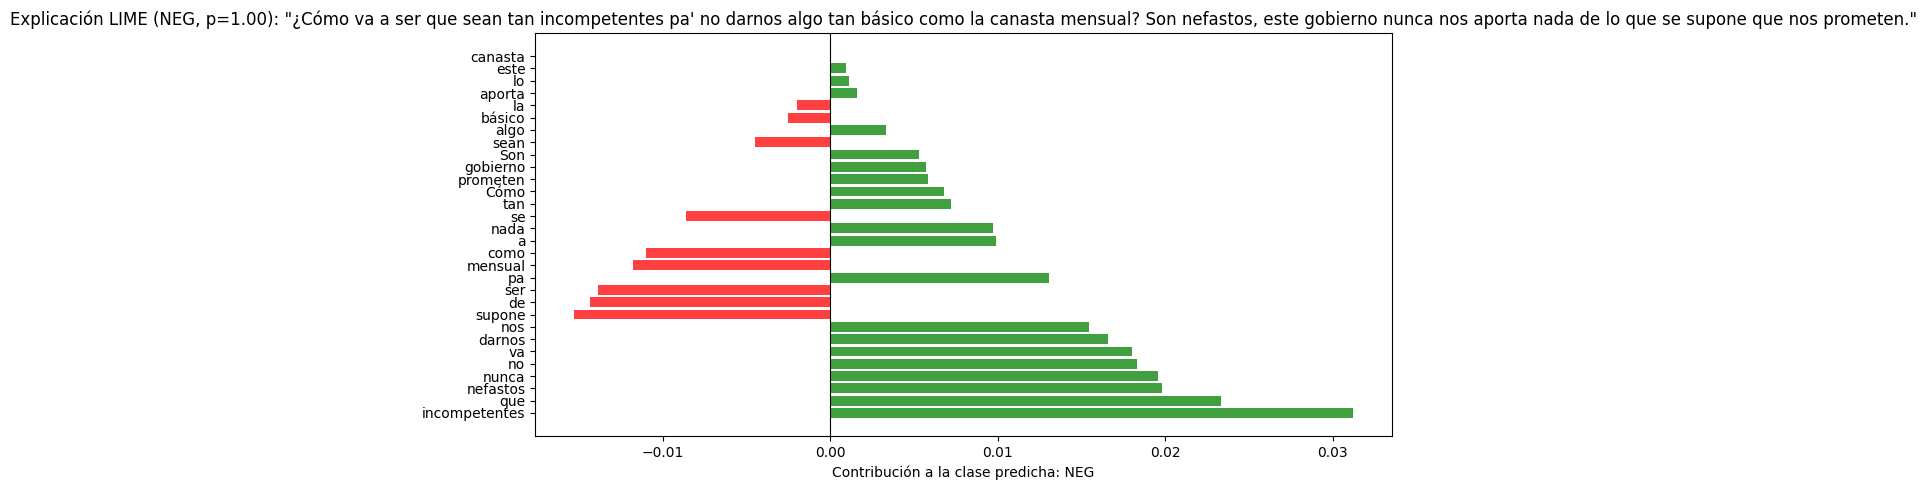


================ LIME - Frase 7 ================


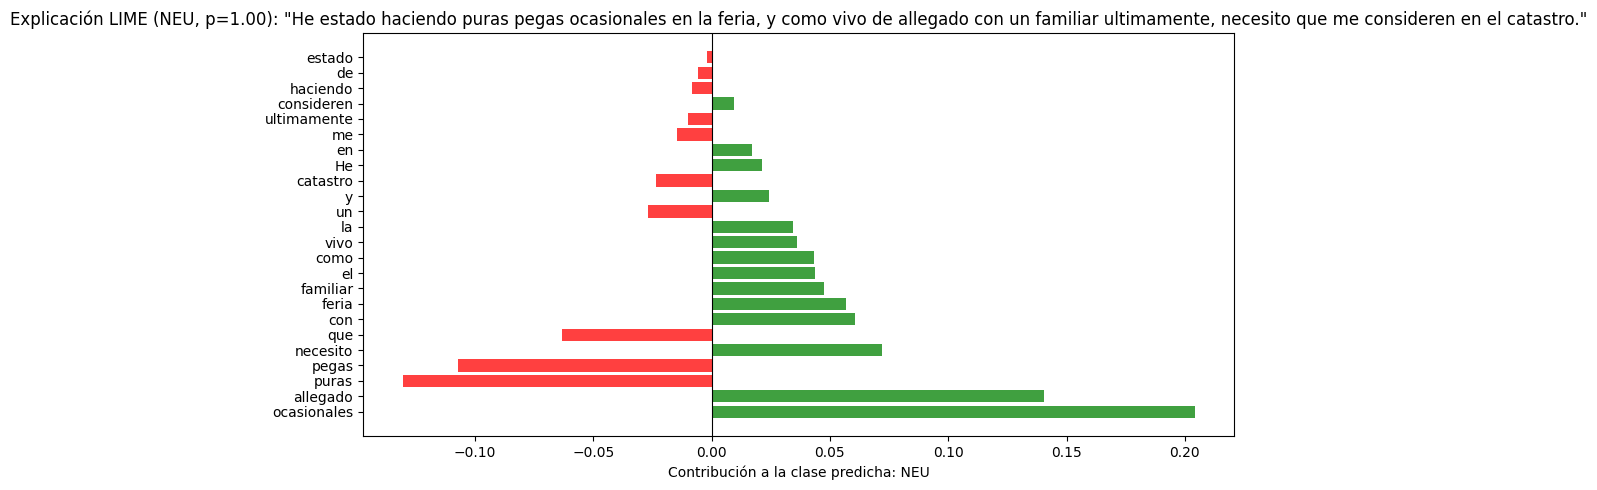


================ LIME - Frase 10 ================


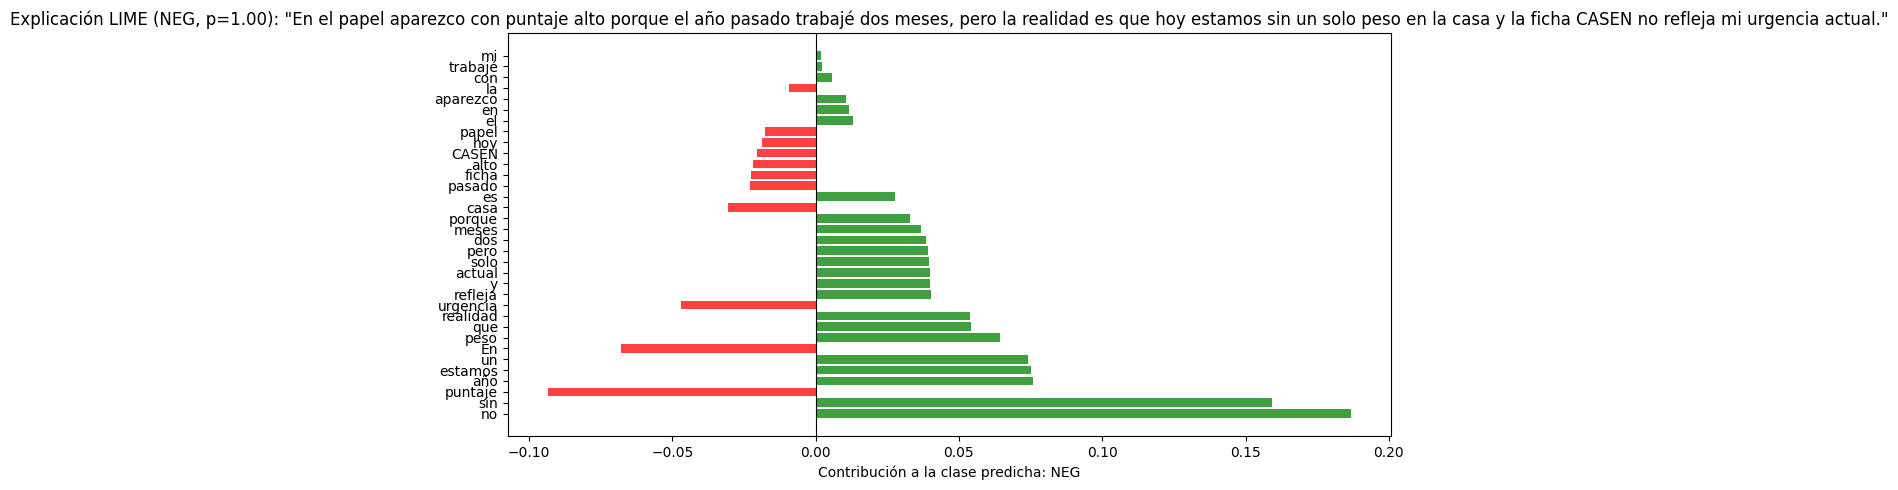

In [6]:
# Índices de las 5 frases elegidas
indices_a_analizar = [0, 1, 4, 6, 9]

for idx in indices_a_analizar:
    frase_a_explicar = frases_casen[idx]
    print(f"\n================ LIME - Frase {idx + 1} ================")

    # Clase predicha por el modelo (este es el código del taller)
    probs = predecir_proba([frase_a_explicar])[0]
    clase_idx = int(np.argmax(probs))
    nombre_clase = explainer.class_names[clase_idx]

    # Obtener explicación para esa clase
    exp = explainer.explain_instance(
        frase_a_explicar,
        predecir_proba,
        labels=(clase_idx,),
        num_features=len(frase_a_explicar.split()),
        num_samples=500
    )

    # Extraemos los pesos (contribuciones) de cada palabra con el código del archivo
    explicacion = exp.as_list(label=clase_idx)
    palabras = [item[0] for item in explicacion]
    pesos    = [item[1] for item in explicacion]

    # Gráfico de barras oficial del taller
    fig, ax = plt.subplots(figsize=(10, 5))
    colores = ['green' if p > 0 else 'red' for p in pesos] # los colores se asignan para ver qué palabras empujan a la clase predicha.
    ax.barh(palabras, pesos, color=colores, alpha=0.75)
    ax.set_xlabel(f'Contribución a la clase predicha: {nombre_clase}')
    ax.set_title(f'Explicación LIME ({nombre_clase}, p={probs[clase_idx]:.2f}): "{frase_a_explicar}"')
    ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    plt.tight_layout()
    plt.show()

Los gráficos de LIME revelan que el modelo de análisis de sentimientos basa sus predicciones en patrones superficiales de lenguaje, en los reclamos y postulaciones formales, las frases 1, 2, 5 y 10, se apoya fuertemente en negaciones, ataques políticos o adjetivos más graves, como "no", "incompetentes", "injusta" y "puntaje". Sin embargo, en el caso de la Frase 7, sobre empleo informal y vivir de allegado, el modelo falla al clasificarla como neutra, ignorando por completo el significado de vulnerabilidad de términos como "ocasionales" o "allegado" al carecer de una carga emocional o de palabras más fuertes.

Esta dinámica expone un sesgo lingüístico y pragmático en los sistemas automatizados de apoyo estatal, el modelo penaliza y etiqueta como negativo cualquier reclamo airado o en jerga coloquial, pero es insensible a situaciones críticas de pobreza si estas se describen en un tono neutro o informal. Desde una perspectiva ética, esto implica que un algoritmo así en la práctica excluiría o desatendería a solicitantes de ayudas sociales que no se expresan con un registro formal o burocrático, resultando en desigualdades estructurales según el nivel socioeducativo de los usuarios.

# Parte 2 : Explicabilidad de Random Forest con SHAP


En esta segunda parte del taller continuarán el trabajo anterior. Usando la limpieza y estandarización que ya realizaron, entrenen ahora un modelo Random Forest. Recuerden que, como mínimo, en la parte anterior debieron haber realizado los siguientes pasos:

2.1 Carga y limpieza de datos

- Revisión de qué columnas tienen nulos o datos faltantes y manejo de estos mediante: 0, botar fila/columna, o imputación de media.

- Revisión del tipo de dato del dataset y de los cambios realizados, si corresponde.

- Codificación de las variables categóricas, ya sea con label encoder, one-hot encoder, dummies, o mapeo manual en caso de columnas binarias.


## `Librerias`

In [1]:
import pandas as pd
import numpy as np
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler,MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


Del taller anterior:

In [2]:
# Cargamos el dataset

file_id = "1DQsXd6hThmoROcqSqVlBPEO-jb0joKj9"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

casen = pd.read_csv(url)

# Dimensiones de la matriz de información
print(casen.shape)
print(f"El dataset tiene {casen.shape[0]} filas y {casen.shape[1]} columnas")

(212471, 42)
El dataset tiene 212471 filas y 42 columnas


En la siguiente celda convertimos a categóricas las columnas que vienen en formato numérico, pero representan códigos de respuesta u opciones cualitativas. Mantener esos códigos como variables numéricas permitiría que el modelo estableciera cortes según su valor, introduciendo un orden que puede no corresponder al significado de las categorías. La conversión permite identificarlas como categóricas y aplicarles después la codificación One-Hot del preprocesamiento.

In [3]:
# Listado de variables que son numéricas pero corresponden a categorías
vars_to_cat = ['p2', 'p3', 'p4', 'p9', 'h7e', 'h7f', 'r14', 'r17a', 'r17b', 'r17c', 'v3', 'v5', 'v23']

# Cambiamos el tipo
for col in vars_to_cat:
    if col in casen.columns:
        casen[col] = casen[col].astype('category')

# Verificamos los cambios
print(casen[vars_to_cat].dtypes)

p2      category
p3      category
p4      category
p9      category
h7e     category
h7f     category
r14     category
r17a    category
r17b    category
r17c    category
v3      category
v5      category
v23     category
dtype: object


Cuantificamos los valores nulos por columna con `casen.isnull().sum()`. La salida guardada muestra cero nulos en todas las columnas, por lo que no fue necesario rellenar valores ni eliminar registros por este motivo. Esta comprobación se refiere a los valores que pandas reconoce como nulos.

In [4]:
# Verificamos la cantidad de nulos por columna
print(casen.isnull().sum())

area             0
p1               0
p2               0
p3               0
p4               0
p9               0
tot_per_h        0
edad             0
sexo             0
ind_hacina       0
e1               0
e9depen          0
o1               0
o19              0
o31              0
s13              0
h7e              0
h7f              0
r1a              0
r3               0
r14              0
r17a             0
r17b             0
r17c             0
v1               0
v2               0
v3               0
v4               0
v5               0
v6               0
v13              0
v20              0
v22              0
v23              0
v24              0
v24b             0
v27a             0
v27b             0
v29b             0
os1              0
trans            0
pobreza_multi    0
dtype: int64


Aunque en esta revisión no se detectaron nulos, conservamos los imputadores del preprocesamiento del Taller 2 para manejar posibles valores faltantes en datos posteriores. Si aparecen, se reemplazarán por la mediana en las variables numéricas y por la moda en las categóricas, calculadas sobre el conjunto de entrenamiento al ajustar el pipeline. En los datos sin nulos, estos pasos no reemplazan ningún valor. La mediana se mantiene como criterio preventivo por su menor sensibilidad a valores extremos respecto del promedio.


2.2 División del conjunto de datos
- separe del conjunto total los predictores y **la variable objetivo **
- Utilice train_test_split para obtener el conjunto de prueba y entrenamiento.

(La variable objetivo no difiere de la utilizada en el taller anterior)

In [5]:
# Definimos la matriz de características (X) y variable objetivo (y)
X = casen.drop(columns=['pobreza_multi'])
# Convertimos la variable objetivo a formato binario (1 para Pobre y 0 para No pobre)
y = casen['pobreza_multi'].apply(lambda x: 1 if str(x).strip().lower() == 'pobre' else 0)

In [6]:
# Dividimos los datos en entrenamiento y testeo (con una seed fija)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

Usamos la misma variable objetivo y la misma división del taller anterior: 80% de los datos para entrenamiento y 20% para prueba. Con `stratify=y` mantenemos una proporción similar de personas pobres y no pobres en ambos conjuntos. Dejamos `random_state=42` para poder repetir los resultados.



2.3 Estandarización
- Estandarice los datos numéricos con StandarScaler o Minmax
- Justifique brevemente su elección






In [7]:
# Identificamos columnas numéricas y categóricas
n_columnas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
c_columnas = X.select_dtypes(include=['object', 'category']).columns.tolist()

In [8]:
# Reutilizamos el preprocesamiento del taller anterior
transformador_n = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_c = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocesador = ColumnTransformer(transformers=[
    ('num', transformador_n, n_columnas),
    ('cat', transformador_c, c_columnas)
])

Tal como hicimos en la entrega anterior, aplicamos StandardScaler en las variables numéricas y codificación One-Hot en las categóricas. Mantenemos StandardScaler para conservar el preprocesamiento del Taller 2 y cumplir con la estandarización solicitada en el enunciado.

No basamos esta elección en supuestos valores atípicos de ingreso o hacinamiento, porque aquí no presentamos un análisis de sus distribuciones que respalde esa afirmación. Tampoco realizamos una comparación que permita concluir que StandardScaler obtiene mejores resultados que MinMax. En un Random Forest, el cambio de escala no es necesario para establecer los cortes de los árboles.

2.4 Clasificador Random Forest y métrica de evaluación
- Entrenen un Random Forest, seleccionen un número de estimadores y entreguen las predicciones del modelo.
- Comenten los resultados de la matriz de confusión y del reporte de clasificación. Expliquen las consecuencias de aplicar ese modelo específico en el área que abarca su proyecto.

Elegimos 100 árboles como configuración inicial, siguiendo la recomendación técnica recibida y buscando equilibrar la agregación de varios árboles con el costo de entrenamiento; no comparamos otros valores, por lo que no lo presentamos como un número óptimo.


In [9]:
# Definimos el random forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42)

In [10]:
# Unimos preprocesamiento y modelo en un Pipeline y lo entrenamos
pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocesador),
    ('classifier', modelo_rf)])

pipeline_rf.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [11]:
# Finalmente evaluamos el rendimiento en el conjunto de testeo
y_pred_rf = pipeline_rf.predict(X_test)

acc = accuracy_score(y_test, y_pred_rf)
cm = confusion_matrix(y_test, y_pred_rf)

print(f"Accuracy al testear: {acc:.5f}")
print("Matriz de Confusión:\n", cm)

print(classification_report(y_test, y_pred_rf))

Accuracy al testear: 0.75522
Matriz de Confusión:
 [[26386  8610]
 [ 1792  5707]]
              precision    recall  f1-score   support

           0       0.94      0.75      0.84     34996
           1       0.40      0.76      0.52      7499

    accuracy                           0.76     42495
   macro avg       0.67      0.76      0.68     42495
weighted avg       0.84      0.76      0.78     42495



Al evaluar el Random Forest, vemos que alcanza un accuracy del 75,5 %, pero la matriz de confusión cuenta una historia más detallada: tenemos 1.792 falsos negativos (personas en situación de pobreza que el modelo consideró no pobres) y 8.610 falsos positivos (personas no pobres a las que etiquetó como pobres).

Si miramos la clase "Pobre", el recall es de 0,76, lo que significa que de cada 100 personas vulnerables, el algoritmo logra captar a unas 76 y deja fuera a 24. Por otro lado, la precisión se sitúa en 0,40: de cada 100 personas que clasifica como pobres, solo unas 40 realmente lo son, mientras que las otras 60 resultan ser falsas alarmas.

Estos números dejan claro por qué guiarse solo por el accuracy es engañoso. Cerca del 82 % de la base de datos pertenece al grupo "No pobre"; si el modelo simplemente predijera que nadie es pobre, sacaría más de un 80 % de puntería global, pero sería completamente inútil para la política social.

El impacto real de estos errores es delicado. Un falso negativo implica dejar sin subsidios estatales a familias que no tienen cubiertas sus necesidades básicas. Peor aún, si ocurre lo mismo que detectamos en el Taller 2, este costo podría recaer con más fuerza en la población indígena o en personas con dificultades de cuidado personal, algo que debemos confirmar revisando los sesgos del bosque por subgrupo. Al mismo tiempo, una cantidad alta de falsos positivos en un sistema automático podría sobrecargar el gasto público y dispersar recursos limitados.

Creemos que calibrar el modelo para no dejar pasar casos vulnerables es el camino correcto, pero con una precisión del 40 % no podemos automatizar las decisiones. Lo más sensato es usar este algoritmo como un filtro inicial de alerta temprana que oriente la revisión de trabajadores sociales, nunca como un juez que otorgue o rechace ayudas por su cuenta.

# DECLARACIÓN DE IA

Durante el desarrollo de mi parte del taller utilicé un asistente de IA para comprender errores de código relacionados con la librería shap sin instalar, el import incompleto ConfusionMa y los imports faltantes de Pipeline, SimpleImputer, ColumnTransformer y classification_report.

También recibí orientación sobre qué partes del Taller 2 reutilizar, en qué orden incorporarlas y qué solicitaba la sección 2.1. Consulté conceptos de escalado, las diferencias entre StandardScaler y MinMax y la lectura de una matriz de confusión, con analogías y un ejemplo inventado de clasificación de spam.

En la etapa de elaboración de mis comentarios, la IA me apoyó con preguntas guía y observaciones sobre la redacción.

Adjunto link: https://claude.ai/share/d93dcb0f-863f-4de7-bcd5-6a1a6d54cf58

2.5 Resultado y explicaciones con SHAP
- Comenta los beneficios y perjuicios que puede tener una herramienta como SHAP, en general y aterriza al caso de los datos trabajados
- Obten los valores shap.Visualiza el summary plot. Comenta los resultados.
- Analiza que features son importantes para la predicción y que puede influir en que estas tengan mayor influencia. Considera en tu explicación la relevancia de los resultados en el contexto.

- Preguntas guía para tu respuesta : ¿Qué aporta conocer los valores SHAP? ¿Es una herramienta suficiente en sí misma o puede apoyarse con otras? ¿Cómo afecta la preparación de los datos a las predicciones y su posterior explicación? ¿Es importante tener acceso a ambas interpretaciónes (global y local) en este caso?

Una herramienta como shap, nos permite saber y concentrarnos en los datos mas relevantes que influyen en los resultados de un entrenamiento de modelo, por lo que nos puede ayudar a tener el conocimiento de que variables son relevantes y de esta forma ayudarnos a tomar posibles desiciones al respecto, esto depende de para que entrenamos el modelo especifico.En nuestro caso con la encuesta CASEN nos ayuda a saber que variables influyen más al clasificar a alguien como pobre/ no pobre y nos puede dar información de que necesitan las personas destacadas como vulnerables dependiendo de la respuesta a sus preguntas(ayuda en la remodelacion de sus casas, tal vez mas construcción de viviendas sociales si existe mucho hacinamiento,etc).
Las contras que puede tener shap son que lo que nos muestra es una relación de las variables y no necesariamente una causa por lo que arreglar lo que "pesa más" en nuestro shap no necesariamente lograria que el efecto desapareciese, en nuestro caso si una variable pesara mucho por ejemplo el hacinamiento de personas, no significaria que si creamos mas viviendas se acaba la pobreza para esas personas, esto se debe a que la pobreza cuesta mucho medirla y combatirla debido a que gran parte de las variables estan relacionadas unas con otras. Lo que nos lleva al siguiente problema que puede tener shap, el cual es que al haber gran cantidad de variables relacionadas entre si, el modelo puede terminar subestimando alguna que tal vez por sí sola no era gran problema pero al relacionarse con otras si que lo es.

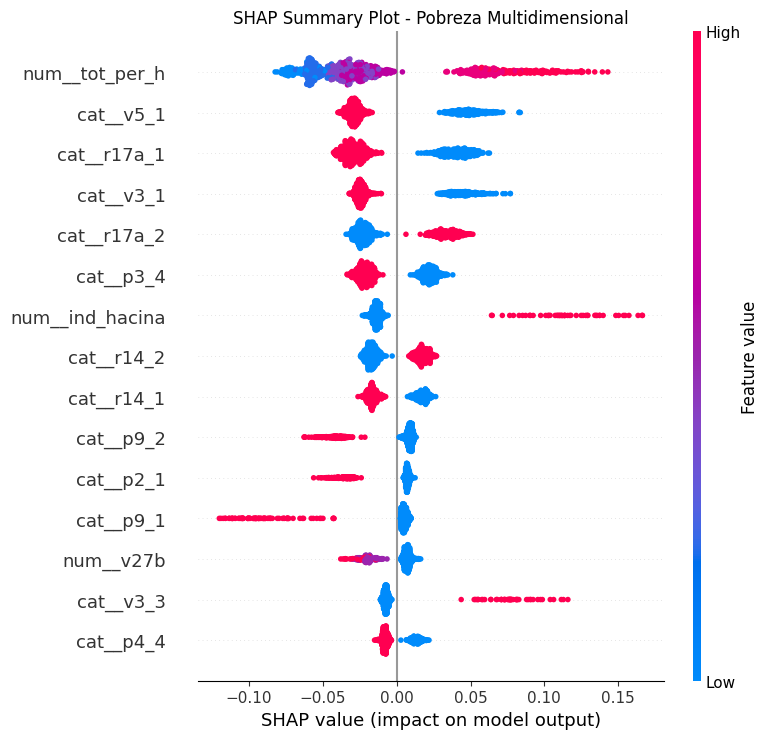

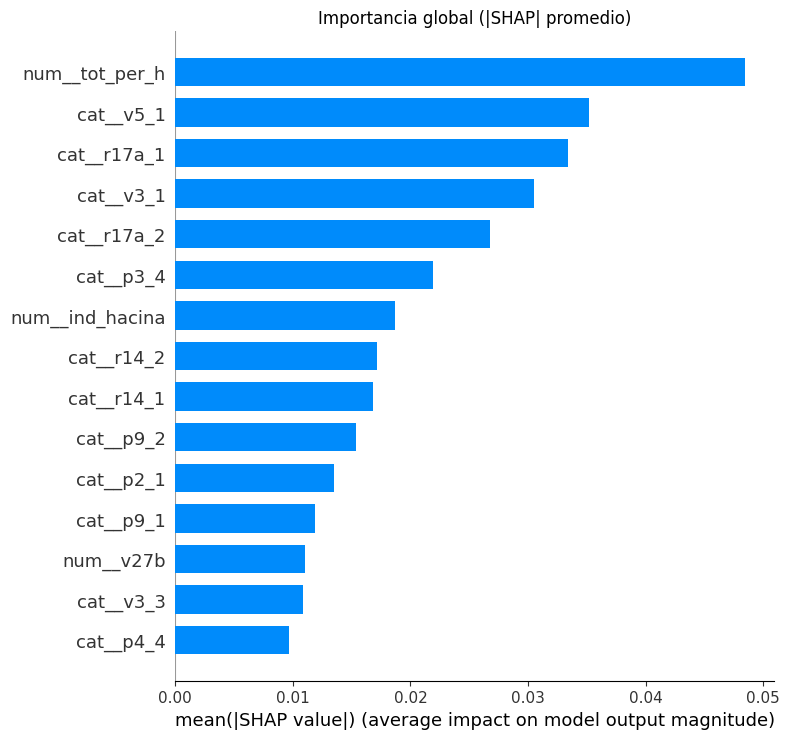

In [14]:
import matplotlib.pyplot as plt #garege el import dnvo pq no lo tomaba de los notebooks de mas arriba ns pq
#no me acorde como hacerlo con DashAI asi q lo hice asi
#  Extraer preprocesador y modelo
preprocessor = pipeline_rf.named_steps['preprocessor']
rf_model = pipeline_rf.named_steps['classifier']

# sacar muestra del test (eran muchos datos y n cargaba nunca si no tomba una muestra)
X_sample = X_test.sample(n=1000, random_state=42)

# 3. Transformar solo la muestra
X_sample_t = preprocessor.transform(X_sample)
if hasattr(X_sample_t, "toarray"):
    X_sample_t = X_sample_t.toarray()

feature_names = preprocessor.get_feature_names_out()
X_sample_df = pd.DataFrame(X_sample_t, columns=feature_names, index=X_sample.index)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_sample_df, check_additivity=False)

#  Seleccionar la clase 1 (Pobre),
if isinstance(shap_values, list):          
    sv = shap_values[1]
elif shap_values.ndim == 3:                
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

#mostrarlo por pantalla
plt.figure()
shap.summary_plot(sv, X_sample_df, plot_type="dot", max_display=15, show=False)
plt.title("SHAP Summary Plot - Pobreza Multidimensional")
plt.tight_layout()
plt.show()


plt.figure()
shap.summary_plot(sv, X_sample_df, plot_type="bar", max_display=15, show=False)
plt.title("Importancia global (|SHAP| promedio)")
plt.tight_layout()
plt.show()

Los factores mas influyentes son: en primer lugar la cantidad de habitantes por hogar , seguidas por variables relacionadas al estado de una vivineda ya sea el estado del piso o de los muros y el indice de hacinamiento. Podria inlfuir en su relevancia el que al haber mas personas en un hogar, especialmente en uno pequeño es mucho mas factible que se deteriore este mas rapido de lo normal o que muchas personas que son parte de ese hogar no contribuyan monetariamente, pero si tengan que ser alimentadas por el sueldo de pocas, por lo que es probable que otras preguntas del catastro sean respondidas de forma que se le asigne vulnerabilidad a estas personas por la correlación de existir muchas personas en un espacio y que no exista el dinero para mantener ese espacio en gran estado. Cabe recalcar tambn que factores como el poseer un vehiculo o tener internet influyen notablemente en mostrar a una persona como no vulnerable.

Conocer los valores shap, tal como lo mencione en un inicio es relevante para entender las variables que son mas relevantes respecto a un modelo.Sin embargo deben de ir acompañadas de mas estudios desde mi punto de vista para corroborar el peso de los datos en la realidad y entender completamente en este caso por ejemplo, que hace que describamos a una persona como vulnerable o pobre. En cuanto a la preparación de datos el one-hot y el imputado y escalado de datos detreminas que columnas ve el modelo y lo que explica el shap, asi q es de suma importancia entender los datos con los que trabajamos. Finalmente si es relevante saber tanto la explicación global y local, ya que la global nos ayuda a entender en este caso los factores que influyen en la población para determinar pobresa y la local nos ayuda a dictamnar el porque un caso en especifico fue clasificado como pobre o no, lo cual nos podria ayudar al tomar desiciones individuales.


# DECLARACIÓN IA

Use a calude debido a que el shap se quedaba cargando infinitamente o al menos mas de 30 min, junto con screenshoots de todo el codigo anterior y como se formo el arbol de desicion + el codigo que llevaba actualmente.  A lo que me recomendo acotar la cantidad de muestras y me dio un codigo igual al que yo llevaba solo que ajustando esa parte e incluyendo el import a matplotlib el cual no entendi pq tenia q importarlo nuevamente el prompt entero es: "llevaba esos codigoes en el trabajo y ahora me pedian hacer esto: Comenta los beneficios y perjuicios que puede tener una herramienta como SHAP, en general y aterriza al caso de los datos trabajados

Obten los valores shap.Visualiza el summary plot. Comenta los resultados.  1. Extraer el preprocesador y el modelo desde el pipeline preprocessor = pipeline_rf.named_steps['preprocessor'] rf_model = pipeline_rf.named_steps['classifier']
 2. Transformar X_test al espacio de features procesadas
X_test_transformed = preprocessor.transform(X_test)
 Si el OneHotEncoder devuelve una matriz dispersa (scipy.sparse), la pasamos a densa
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()
 3. Recuperar los nombres reales de las columnas generadas
feature_names = preprocessor.get_feature_names_out()
 Crear un DataFrame con los nombres correctos para que SHAP los muestre en el gráfico
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)
 4. Crear el TreeExplainer y calcular valores SHAP
 Nota: Si X_test es muy grande, puedes tomar una muestra: shap.sample(X_test_df, 500)
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test_df)
 En clasificación binaria, seleccionamos la clase 1 (Pobreza Multidimensional)
 Dependiendo de la versión de SHAP, shap_values puede tener 3 dimensiones (samples, features, classes)
if len(shap_values.shape) == 3:
    shap_values_target = shap_values[:, :, 1]
else:
    shap_values_target = shap_values
 5. Summary Plot tipo Beeswarm (impacto y dirección)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_target, X_test_df, plot_type="dot", max_display=15, show=False)plt.title("SHAP Summary Plot - Factores determinantes de Pobreza Multidimensional", fontsize=13)
plt.tight_layout()
plt.show()
 6. Summary Plot tipo Bar (importancia global por magnitud promedio)
plt.figure(figsize=(12, 6))
shap.summary_plot(shap_values_target, X_test_df, plot_type="bar", max_display=15, show=False)
plt.title("Importancia Global de Variables (|SHAP value| promedio)", fontsize=13)
plt.tight_layout()
plt.show() el problema es q se queda cargando indefinidamente en mi jupyter"

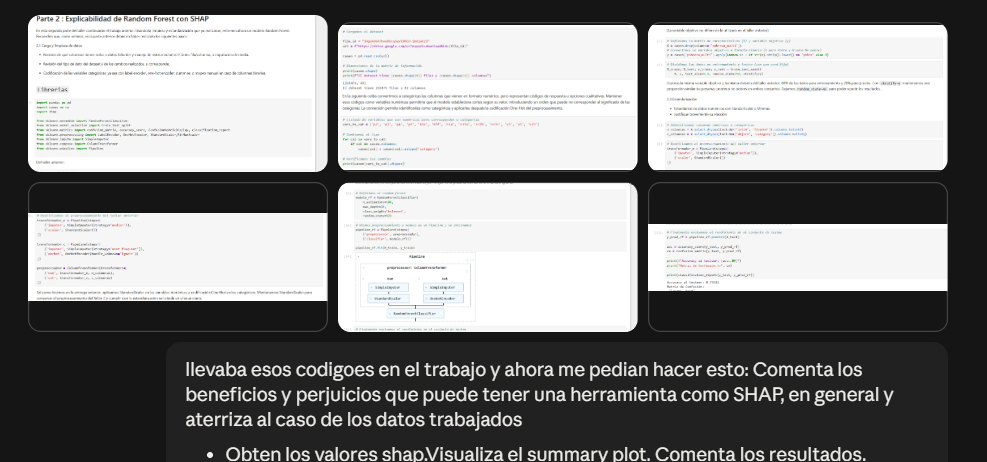

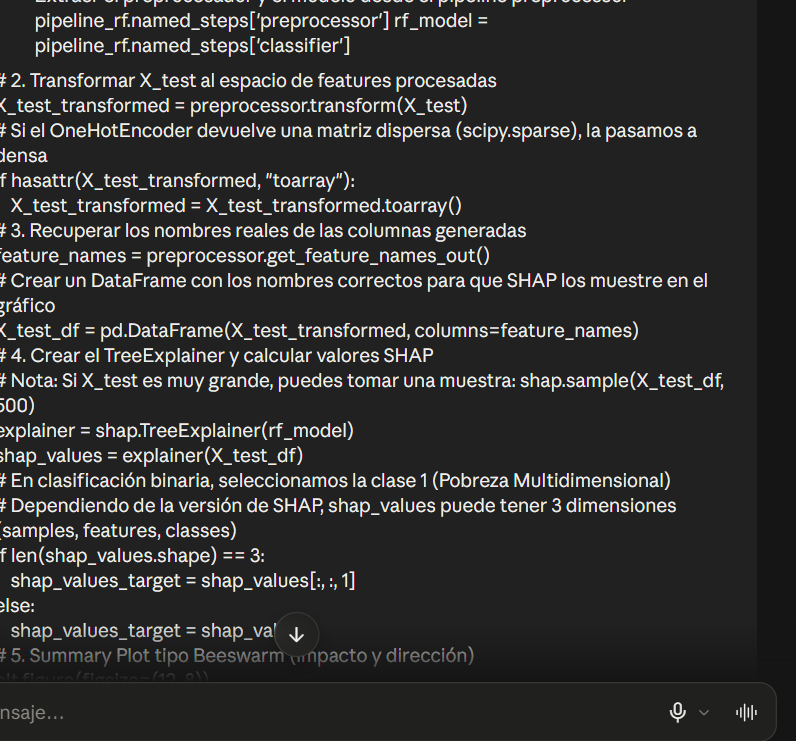

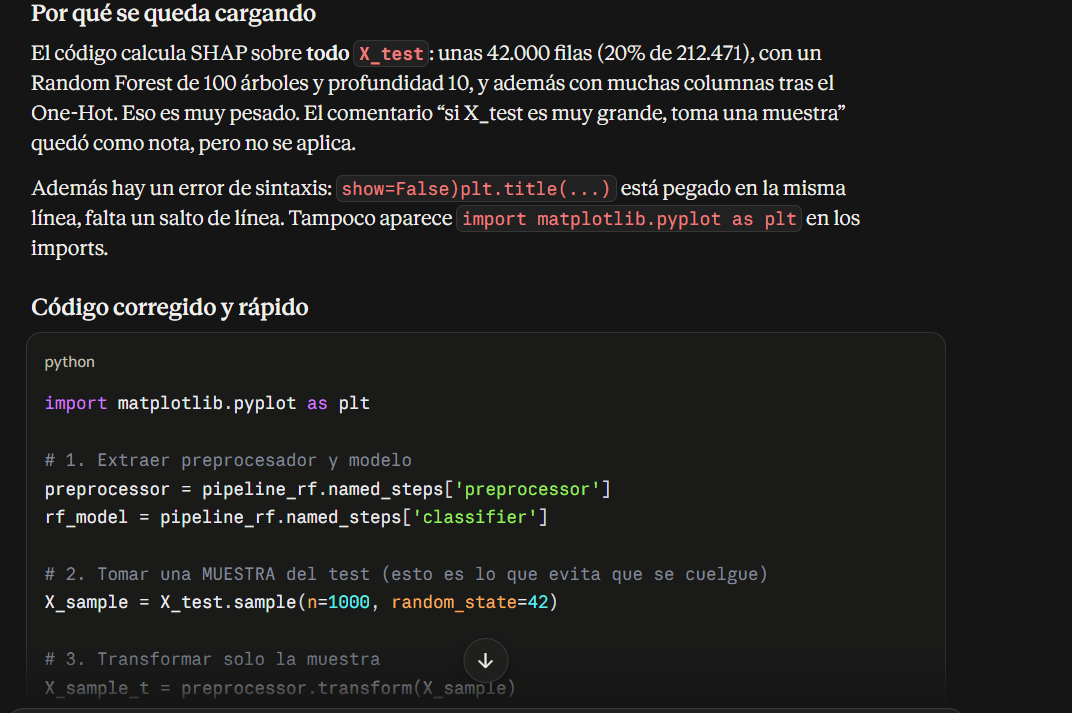

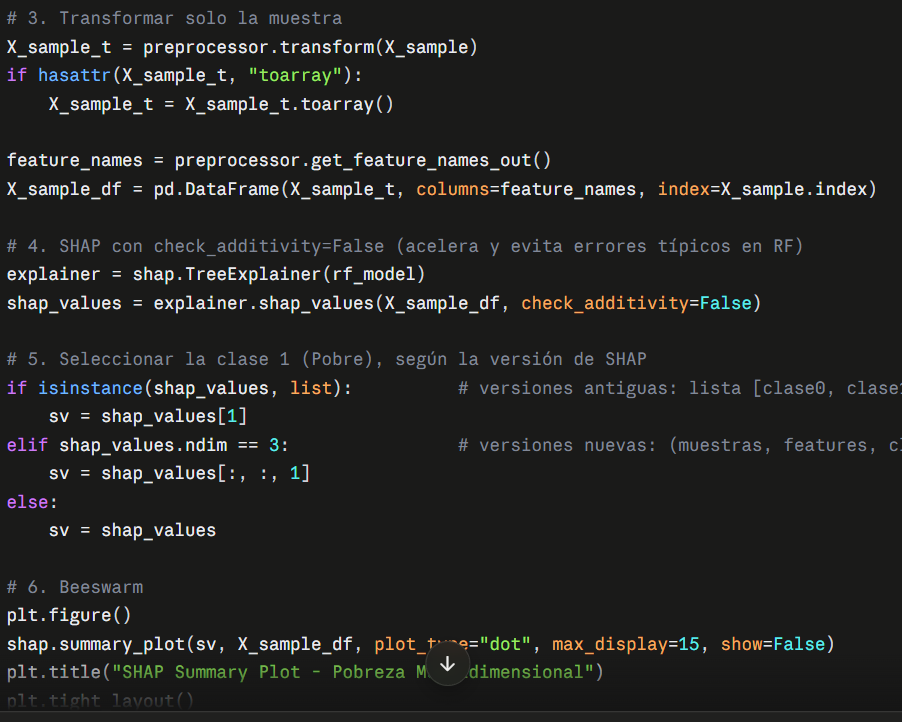